Step 11: interop: adding figures, graphs and other objects to a drawing with ``doc.add``.

``Document.add`` accepts more than elements: a matplotlib figure, a networkx graph, an object with
``__svgwriter__``, ``_repr_svg_`` or ``_repr_png_``. Each becomes native elements you can place, scale and
restyle. Matplotlib and networkx are optional; their cells are skipped when they are not installed.
Run it as ``python 11_interop.py`` or open ``11_interop.ipynb`` to see each step.

In [1]:
import importlib.util
import os
import tempfile
from pathlib import Path

import numpy as np

import svgwriter as svg
from svgwriter.elements.structure import Pixels

A board of three columns by two rows. Each cell is added and placed by its top-left corner with
`place(x, y, at="top_left")`.

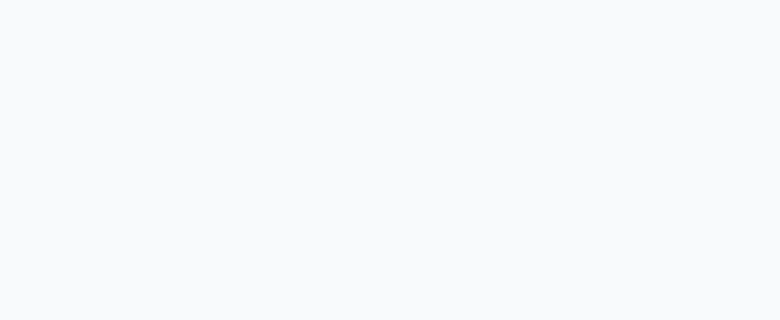

In [2]:
CELL_W, CELL_H = 260, 160
doc = svg.Document(3 * CELL_W, 2 * CELL_H)
doc.rect(0, 0, 3 * CELL_W, 2 * CELL_H, fill="#f8fafc")


def cell(column: int, row: int) -> tuple[float, float]:
    """Top-left corner of a board cell, with a margin."""
    return column * CELL_W + 12, row * CELL_H + 12


doc

A matplotlib figure goes straight into `add`: it is saved as SVG, parsed and kept as a group of paths
and text, so the plot can be scaled, recolored and exported with the rest of the drawing.

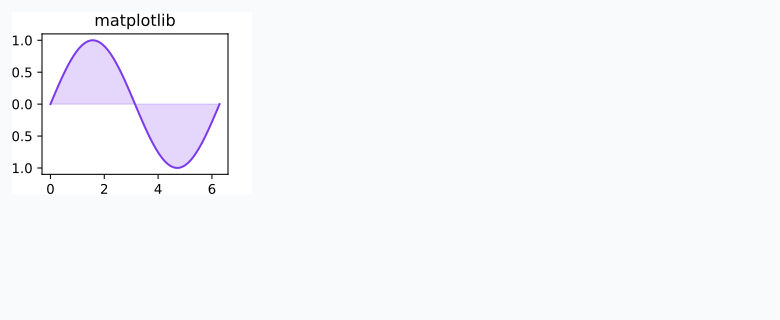

In [3]:
if importlib.util.find_spec("matplotlib") is not None:
    import matplotlib

    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    fig, ax = plt.subplots(figsize=(2.5, 1.9))
    x = np.linspace(0, 2 * np.pi, 60)
    ax.plot(x, np.sin(x), color="#7c3aed")
    ax.fill_between(x, np.sin(x), alpha=0.2, color="#7c3aed")
    ax.set_title("matplotlib")
    doc.add(fig).place(*cell(0, 0), at="top_left")
    plt.close(fig)
doc

A networkx graph is drawn as circles, lines and labels (`layout=` and the node and edge attributes
restyle it; `svgwriter.ops.draw_graph` takes the same options). It comes in 400 units wide, so it is scaled down.

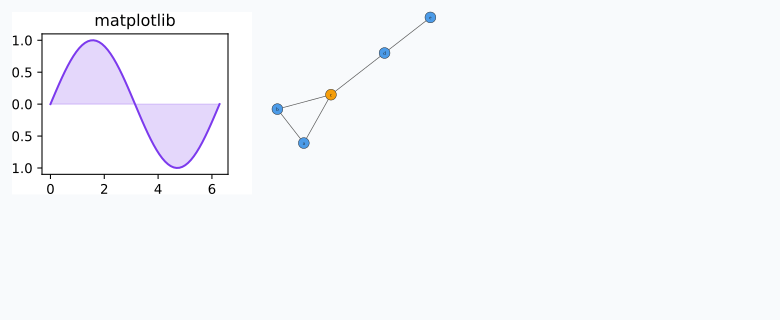

In [4]:
if importlib.util.find_spec("networkx") is not None:
    import networkx as nx

    graph = nx.Graph([("a", "b"), ("b", "c"), ("c", "a"), ("c", "d"), ("d", "e")])
    graph.nodes["c"]["fill"] = "#f59e0b"
    doc.add(graph).scale(0.45).place(*cell(1, 0), at="top_left")
doc

An object with `__svgwriter__` returns what to draw: an element, a document or another object `add`
accepts. This is the hook for your own classes.

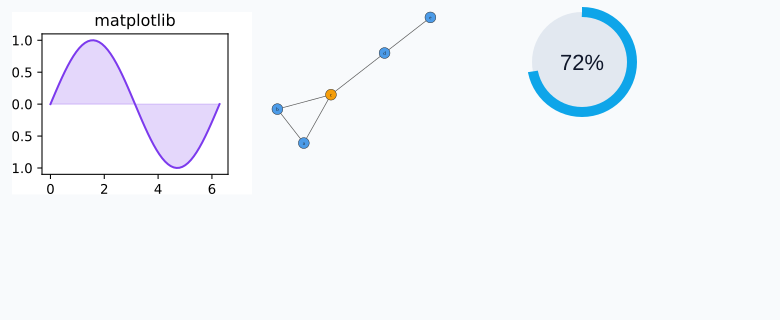

In [5]:
class Gauge:
    """A dial reading ``value`` from 0 to 1."""

    def __init__(self, value: float) -> None:
        self.value = value

    def __svgwriter__(self) -> svg.Group:
        dial = svg.Group()
        dial += svg.circle(60, 60, 50, fill="#e2e8f0")
        dial += svg.circle(60, 60, 50, fill="none", stroke="#0ea5e9", stroke_width=10,
                           stroke_dasharray=(314 * self.value, 314), transform="rotate(-90 60 60)")
        dial += svg.text(f"{self.value:.0%}", x=60, y=68, font_size=22, text_anchor="middle", fill="#0f172a",
                         font_family="Arial, Helvetica, sans-serif")
        return dial


doc.add(Gauge(0.72)).place(*cell(2, 0), at="top_left")
doc

`_repr_svg_` is the IPython display protocol, so plotting and diagram libraries that follow it work
unchanged. Its SVG is parsed into elements.

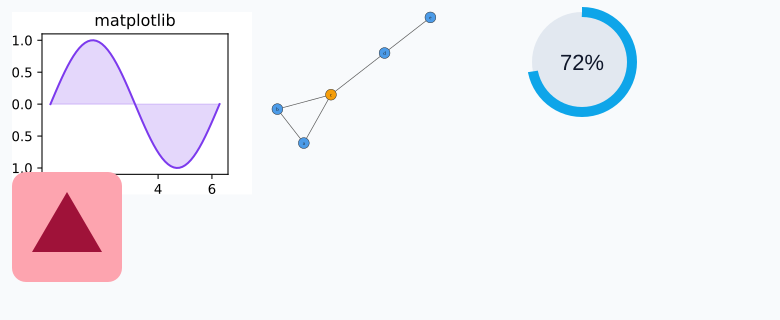

In [6]:
class Swatch:
    """Anything that renders itself with ``_repr_svg_``."""

    def _repr_svg_(self) -> str:
        return (
            '<svg xmlns="http://www.w3.org/2000/svg" width="110" height="110" viewBox="0 0 110 110">'
            '<rect width="110" height="110" rx="14" fill="#fda4af"/>'
            '<path d="M20 80 L55 20 L90 80 Z" fill="#9f1239"/></svg>'
        )


doc.add(Swatch()).place(*cell(0, 1), at="top_left")
doc

`_repr_png_` (or `_repr_jpeg_`) gives bytes of a raster image, which become an `<image>`, and a numpy
array is an `<image>` as well.

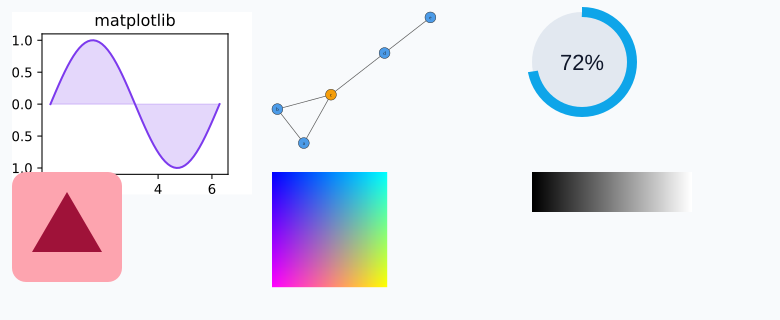

In [7]:
class Heat:
    """Raster-only: PNG bytes from ``_repr_png_``."""

    def _repr_png_(self) -> bytes:
        u, v = np.mgrid[0:64, 0:64] / 63
        return Pixels.from_array(np.dstack([u, v, 1 - u * v])).encode("png")


doc.add(Heat()).scale(1.8).place(*cell(1, 1), at="top_left")
ramp = np.tile(np.linspace(0, 1, 64), (16, 1))
doc.add(ramp).scale(2.5).place(*cell(2, 1), at="top_left")
doc

Save the board. Set `SVGWRITER_EXAMPLES_OUT` to choose the folder.

In [8]:
out = Path(os.environ.get("SVGWRITER_EXAMPLES_OUT") or tempfile.mkdtemp(prefix="svgwriter-"))
out.mkdir(parents=True, exist_ok=True)
doc.save(out / "11_interop.svg")
print("saved 11_interop.svg")

saved 11_interop.svg
